'''
Random forrest

#TODO write more :)


'''

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier


class DataLoader:
    '''
    Dataloader to use before I get the real one
    '''

    def __init__(self):
        '''
        Initialize the class function
        '''

    def get_data(self):
        '''
        :param Input: Datalocation
        :print: Optional datainfo.
        :return: Output: Dataframe
        '''
        # df = pd.DataFrame(pd.read_excel("gallstone_fully_cleaned_for_rf.xlsx"))
        # df = pd.DataFrame(pd.read_excel("dataset-uci1.xlsx"))
        df = pd.DataFrame(pd.read_csv("dataset_uci_testing_set.csv"))
        # for col in df.columns:
        #     if df[col].isin([0, 1]).all():
        #         df[col] = df[col].astype(bool)
        # print("1")

        # print(df.head())
        # print(list(df)) # print the headers
        #print(df.describe().T)
        # idx = df["Obesity (%)"].idxmax()
        # print(df.loc[idx])
        
        # df.info()
       
        #print(df.head()) # print the first 5 rows of the dataframe

        return df
        
      
# Local_df = DataLoader.get_data(self=DataLoader)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn import tree

class RandomForrest:
    '''Random Forest model for predicting gallstone status.
    
    Args
    -----
        random_state: random seed
        test_size: The size for how much should be kept as training
        target: "Gallstone_Status"
        features: Selectec features to train and validate model on

    Attributes
    -------
        df: DataFrame loaded by DataLoader
        model: Fitted random forest classifier after train_mode
        X_train: Training features
        X_test: Test features
        y_train: Training target values
        y_test: Test target values

    Methods
    --------
        split_data: Create stratified training and test sets
        train_model: Fit the classifier, report metrics, show plots, and return
        the fitted model
    
    
    '''

    def __init__(self, random_state = 77, test_size = 0.2, target = None, features = None):
        """
        # Init the class Randomforrest:

          
        Definition
        ----------
            split_data() : Initiate splitting of the data
        
        """
        self.random_state = random_state
        self.df = DataLoader().get_data()
        self.model = None
        self.test_size = test_size
        self.target = target
        self.features = features
        self.split_data()

    def split_data(self):
        """
        Splitting the data to prepare for the model training
        """
        X = self.df[self.features]
        y = self.df[self.target]
        print("Data split")
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
                    X, y, test_size = self.test_size, stratify = y, random_state = self.random_state)
        
        # stratify = y ensure equal distribution of target = "Gallstone Status" with train and test data.

    def train_model(self, **params):
        """
        Trains the model on the split data
        """
        defaults = dict(n_estimators = 1000, max_features = 0.3, max_depth = 4,
                        min_samples_leaf = 3, criterion = "entropy",
                        oob_score = True, n_jobs = -1, random_state  = self.random_state,
                        bootstrap = True, warm_start = False)
        defaults.update(params) # Update defaults with new parameters
        
        self.model = RandomForestClassifier(**defaults)
        self.model.fit(self.X_train, self.y_train)
        
        # Get predicted class probabilities for the test set
        y_pred_prob = self.model.predict_proba(self.X_test)[:, 1]
        predictions = self.model.predict(self.X_test)
        train_score = self.model.score(self.X_train, self.y_train)
        test_score = self.model.score(self.X_test, self.y_test)

        print(f"OOB accuracy:  {self.model.oob_score_:.3f}")
        print(f"Test accuracy: {accuracy_score(self.y_test, predictions):.3f}")
        print(f"ROC AUC Score: {roc_auc_score(self.y_test, y_pred_prob):.3f}\n")
        print("Classification report")
        print(classification_report(self.y_test, predictions))
        
        print(f"Train accuracy: {train_score:.3f}")
        print(f"Test accuracy: {test_score:.3f}")
        print(f"Overfit gap: {train_score - test_score:.3f}")

        '''
        https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html
        '''
        cm = confusion_matrix(self.y_test, predictions, labels=self.model.classes_)
        

        '''
        https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html
        https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
        https://www.geeksforgeeks.org/machine-learning/calculate-roc-auc-for-classification-algorithm-such-as-random-forest/
        '''

        # plot
        fig, ax =  plt.subplots(1, 2, figsize=(12, 5))
        ConfusionMatrixDisplay.from_predictions(self.y_test, predictions, ax = ax[0], cmap = "Blues")
        ax[0].set_title("Confusion matrix")
        RocCurveDisplay.from_predictions(self.y_test, y_pred_prob, ax = ax[1])
        ax[1].plot([0, 1], [0, 1], "k--")
        ax[1].set_title("ROC curve")  
        plt.tight_layout()
        plt.show()
        defaults_clf = dict(max_features = 0.3, max_depth = 4,
                        min_samples_leaf = 3, criterion = "entropy",
                        random_state  = self.random_state,
                        )
        # Not a random forrest, but a single tree
        # Visualizing the decision
        clf = tree.DecisionTreeClassifier(**defaults_clf)
        clf.fit(self.X_train, self.y_train)
        plt.figure(figsize = (12, 12), dpi = 300)
        #tree.plot_tree(clf)
        tree.plot_tree(self.model.estimators_[0], feature_names=list(self.X_train.columns), class_names=["0", "1"], 
                       filled = True, max_depth = 4, fontsize = 4)
        plt.show()

        return self.model


# # Only used for making the cell and tuning parameters, obsolete, but keeping around
# if __name__ == "__main__": # ONly run when the code is run directly.
#     rf = RandomForrest(random_state = 14, test_size = 0.2) # Initiate RandomForrest with test_size = 0.3
#     rf.train_model() # Calling train_model with params
#     # rf.train_model(n_estimators = 500, max_features = "sqrt", max_depth = None,
#                 # min_samples_leaf = 2, criterion = "entropy", random_state  = 14,
#                 # min_samples_split = 5
#                 # ) # Trying different params to see if it improves accuracy



If the curve stays above the diagonal line, generally means the model ranks positive cases better than random.
The closer to the top left corner, the better the trade of between finding positives and avoiding false positives.

# FIX WITH CORRECT NUMBERS
38 were actually False and predicted False.

10 were actually False but predicted True — false positives.

12 were actually True but predicted False — false negatives.

36 were actually True and predicted True.

In [26]:
"""
RandomForrestValidation
Validate/use the training set from RandomForrest
"""
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

class RandomForrestValidation:
    """
    Uses a unseen dataset to validate/test the trained model

    Validation data: dataset_uci_validation_set.csv.

    Args
    -----
        target: "Gallstone_Status"
        features: Selectec features to train and validate model on

    Attributes
    -----
        df_unseen: DataFrame containing the unseen validation data
        X_new: Feature data passed to the model during evaluation
        y_new: Actual target values from the validation data

    Methods
    -----
        evaluate: Predict labels and class-1 probabilities, report evaluation
        metrics, display plots, and show a preview of the results
   
    
    """
    def __init__(self, target = None, features = None):
        """
        Load validation dataset
        """
        self.df_unseen = pd.read_csv("dataset_uci_validation_set.csv")
        self.target = target
        self.features = features

    def evaluate(self, model):
        """
        Evaluate the trained model against unseen data
        """
        self.X_new = self.df_unseen[self.features]
        pred = model.predict(self.X_new)
        y_pred_prob = model.predict_proba(self.X_new)[:, 1]

        out = self.X_new[self.features].copy()
        out["P(class 1)"] = y_pred_prob.round(2)
        out["Predicted"]  = pred
        out["Actual"] = self.df_unseen[self.target].to_numpy()
        out["Correct"] = out["Predicted"] == out["Actual"]
        self.y_new = self.df_unseen[self.target]

        # plot
        print(f"Unseen accuracy: {accuracy_score(self.y_new, pred):.3f}  (n = {len(self.y_new)})")
        print(f"Unseen ROC-AUC:  {roc_auc_score(self.y_new, y_pred_prob):.3f}")
        print(classification_report(self.y_new, pred))
        print(f"ROC AUC Score: {roc_auc_score(self.y_new, y_pred_prob):.3f}")
        fig, ax =  plt.subplots(1, 2, figsize=(12, 5))
        ConfusionMatrixDisplay.from_predictions(self.y_new, pred, ax = ax[0], cmap = "Blues")
        ax[0].set_title("Confusion matrix (unseen data)")
        RocCurveDisplay.from_predictions(self.y_new, y_pred_prob, ax = ax[1])
        ax[1].plot([0, 1], [0, 1], "k--")
        ax[1].set_title("ROC curve (unseen data)")
        plt.tight_layout()
        plt.show()

        display(out.head(30))


# validation = RandomForrestValidation()
# validation.evaluate(rf.model)

PREFERED_FEATURES = [
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Hyperlipidemia'
]
 
PREFERED_FEATURES_13=[
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    "Extracellular Fluid/Total Body Water (ECF/TBW)",
    'Hyperlipidemia',
    'Gender',
    'High Density Lipoprotein (HDL)',
    'Aspartat Aminotransferaz (AST)',
    'Creatinine',
    'Alkaline Phosphatase (ALP)',
    'Diabetes Mellitus (DM)'
]

In [27]:
"""
Automatic parameter search, not very usefull for our case
"""

# from sklearn.model_selection import GridSearchCV
# from sklearn.ensemble import RandomForestClassifier

# # param_grid = {
# #     'n_estimators': [100, 200],
# #     'max_depth': [None, 10, 20],
# #     'min_samples_split': [2, 5],
# #     'min_samples_leaf': [1, 2],
# #     'bootstrap': [True, False]
# # }

# param_grid = {
#     "n_estimators": [100, 500, 1000], 
# #     "max_features": ["sqrt", "log2", None, 0.3],
#     "max_depth": [None, 4, 6],
#     "min_samples_split": [2, 5],
#     "min_samples_leaf": [2, 3 ,5], 
# #     "criterion": ["gini", "entropy", "log_loss"]
# }

# grid_search = GridSearchCV(RandomForestClassifier(), param_grid=param_grid, cv = 5, verbose = 2)
# grid_search.fit(rf.X_train, rf.y_train)

# print("Best Parameters:", grid_search.best_params_)
# print("Best Estimator:", grid_search.best_estimator_)

# """
# https://www.geeksforgeeks.org/machine-learning/random-forest-hyperparameter-tuning-in-python/
# """

# """
# Alternative
# https://medium.com/data-science/hyperparameter-tuning-the-random-forest-in-python-using-scikit-learn-28d2aa77dd74
# """

'\nAutomatic parameter search, not very usefull for our case\n'

Test ran
Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best Estimator: RandomForestClassifier(criterion='entropy', max_depth=5, min_samples_leaf=2)

### 1 hour run        
Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best Estimator: RandomForestClassifier(criterion='entropy', max_depth=5, min_samples_leaf=2)

### Short run
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 500}
Best Estimator: RandomForestClassifier(min_samples_leaf=2, min_samples_split=5,

Forklar hvorfor feature select ikke gir et bedre resultat.

Data split
OOB accuracy:  0.758
Test accuracy: 0.828
ROC AUC Score: 0.842

Classification report
              precision    recall  f1-score   support

           0       0.79      0.90      0.84        29
           1       0.88      0.76      0.81        29

    accuracy                           0.83        58
   macro avg       0.83      0.83      0.83        58
weighted avg       0.83      0.83      0.83        58

Train accuracy: 0.887
Test accuracy: 0.828
Overfit gap: 0.060


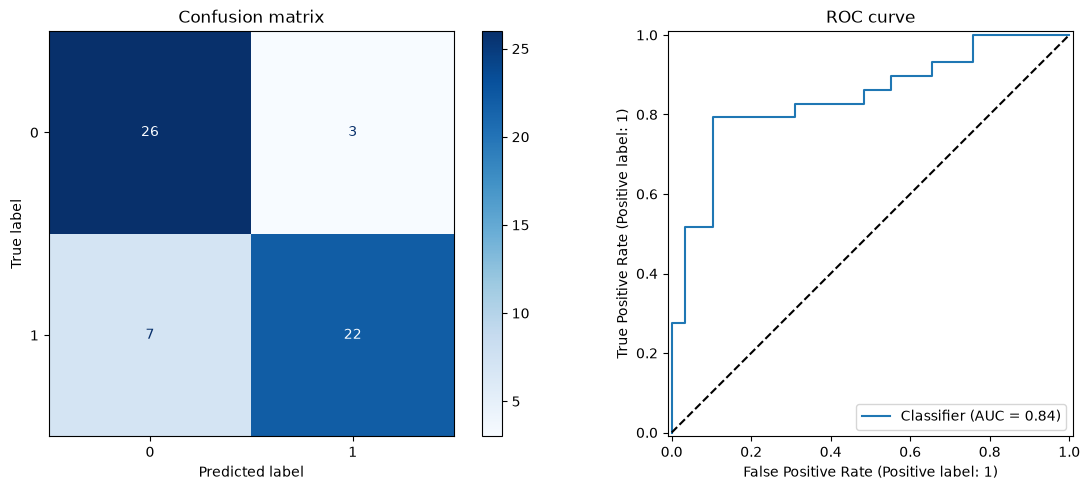

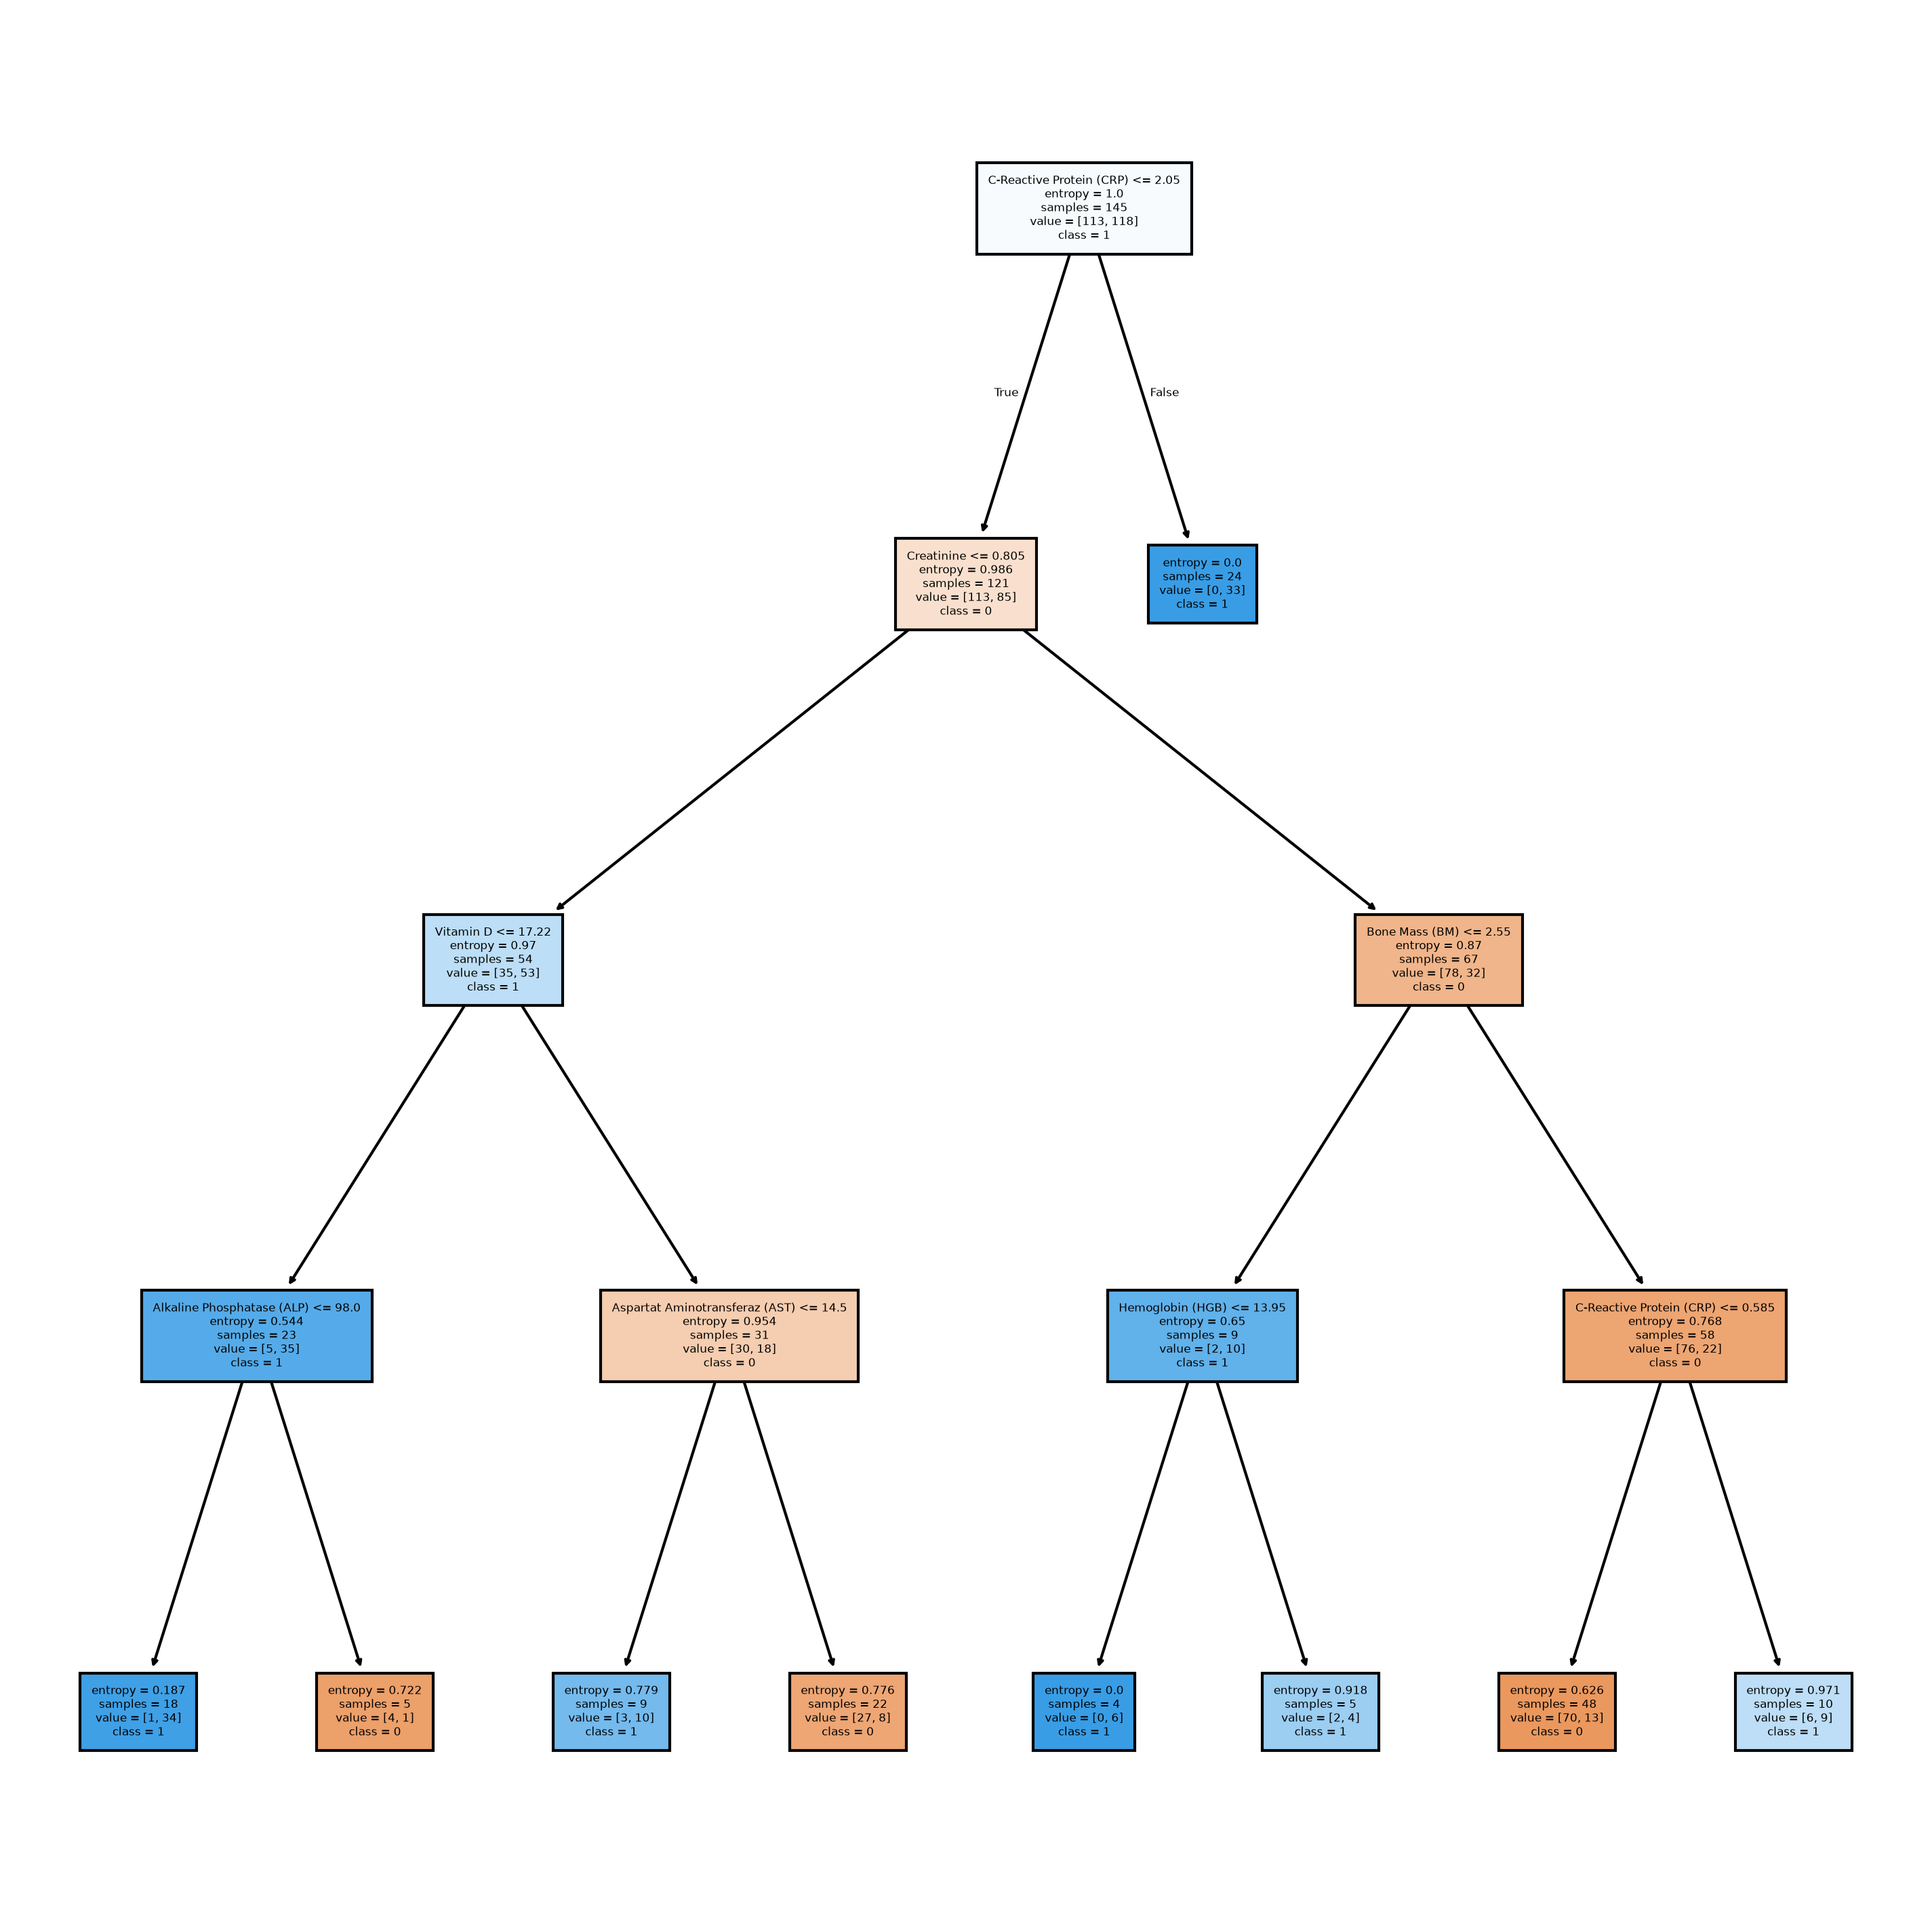

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.3
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",14
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Be

In [28]:
"""
Selecting FEATURE and calling the RandomForrest class for training
"""


FEATURES_FIRST_DRAFT = [
                    "Age",
                    "Body Mass Index (BMI)",
                    "Total Body Fat Ratio (TBFR) (%)",
                    "Visceral Fat Rating (VFR)",
                    "Visceral Fat Area (VFA)",
                    "Glucose",
                    "Total Cholesterol (TC)",
                    "Low Density Lipoprotein (LDL)",
                    "High Density Lipoprotein (HDL)",
                    "Triglyceride",
                    "Vitamin D"
                ]
PREFERED_FEATURES_13 = [
                    'Vitamin D',
                    'C-Reactive Protein (CRP)',
                    'Total Body Fat Ratio (TBFR) (%)',
                    'Bone Mass (BM)',
                    'Hemoglobin (HGB)',
                    "Extracellular Fluid/Total Body Water (ECF/TBW)",
                    'Hyperlipidemia',
                    'Gender',
                    'High Density Lipoprotein (HDL)',
                    'Aspartat Aminotransferaz (AST)',
                    'Creatinine',
                    'Alkaline Phosphatase (ALP)',
                    'Diabetes Mellitus (DM)'
                ]

target = "Gallstone Status"

feature_select = 3
match feature_select:
    case 1:
        self.df = DataLoader().get_data()
        FEATURES = self.df.drop(columns=[target])
        #FEATURES = self.df.drop(columns=[target]).columns.tolist()
    case 2:
        FEATURES = FEATURES_FIRST_DRAFT
    case 3:
        FEATURES = PREFERED_FEATURES_13
    


rf = RandomForrest(random_state = 14, test_size = 0.2, target = target, features = FEATURES) # Initiate RandomForrest with test_size = 0.3
rf.train_model() # Calling train_model with params
# rf.train_model(n_estimators = 500, max_features = "sqrt", max_depth = None,
            # min_samples_leaf = 2, criterion = "entropy", random_state  = 14,
            # min_samples_split = 5
            # ) # Trying different params to see if it improves accuracy

Unseen accuracy: 0.700  (n = 30)
Unseen ROC-AUC:  0.818
              precision    recall  f1-score   support

           0       0.69      0.73      0.71        15
           1       0.71      0.67      0.69        15

    accuracy                           0.70        30
   macro avg       0.70      0.70      0.70        30
weighted avg       0.70      0.70      0.70        30

ROC AUC Score: 0.818


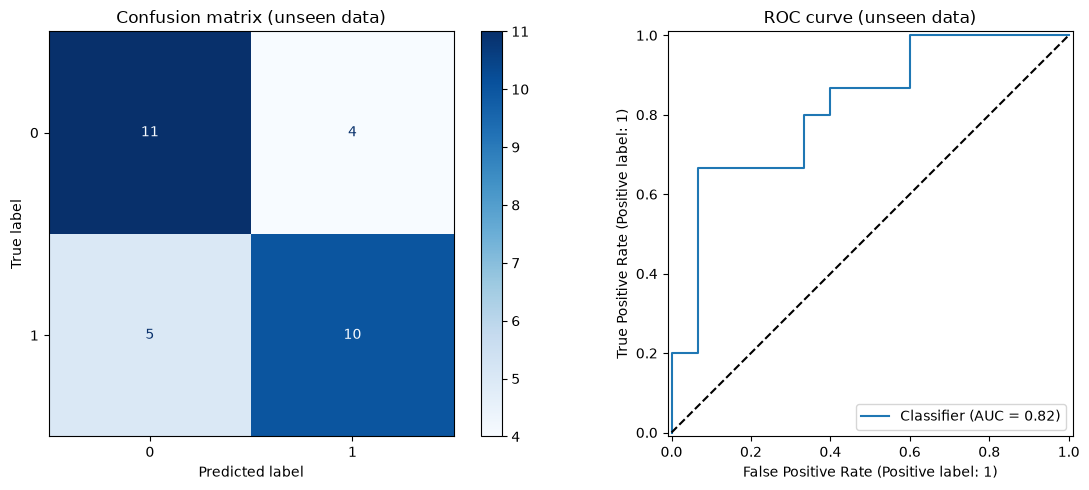

,Vitamin D,C-Reactive Protein (CRP),Total Body Fat Ratio (TBFR) (%),Bone Mass (BM),Hemoglobin (HGB),Extracellular Fluid/Total Body Water (ECF/TBW),Hyperlipidemia,Gender,High Density Lipoprotein (HDL),Aspartat Aminotransferaz (AST),Creatinine,Alkaline Phosphatase (ALP),Diabetes Mellitus (DM),P(class 1),Predicted,Actual,Correct
0,21.500000,16.50,50.92,3.0,10.90,45.00,0,1,74.0,13.0,0.650,77.0,1,0.86,1,1,True
1,25.150000,0.00,20.20,3.4,15.70,40.00,0,0,39.0,22.0,0.820,73.0,0,0.17,0,0,True
2,15.000000,0.00,42.80,2.7,13.20,47.00,0,1,53.0,17.0,0.830,68.0,0,0.42,0,1,False
3,8.700000,0.84,22.90,2.9,17.30,44.00,0,0,47.0,27.0,0.960,97.0,0,0.60,1,0,False
4,24.000000,7.00,41.17,2.2,12.20,37.40,0,1,48.0,17.0,0.720,106.0,0,0.84,1,1,True
5,26.900000,1.63,27.90,3.6,14.25,40.00,0,0,46.5,20.5,0.725,91.0,0,0.49,0,1,False
6,8.400000,3.70,20.30,2.7,17.00,42.00,0,0,45.0,60.0,0.920,90.0,0,0.78,1,1,True
7,6.300000,0.80,34.30,2.7,13.70,44.00,0,1,42.0,14.0,0.700,52.0,0,0.68,1,1,True
8,21.800000,0.78,42.20,2.7,10.70,47.00,0,1,57.0,18.0,0.630,92.0,0,0.59,1,0,False
9,21.000000,0.90,41.65,2.6,13.90,39.10,0,1,57.0,15.0,0.640,107.0,0,0.69,1,1,True


In [ ]:
"""
Using the same FEATURES as RandomForrest class
Calling RandomForrestValidation class to test on unseen data
"""

validation = RandomForrestValidation(target = target, features = FEATURES)
validation.evaluate(rf.model)

In [30]:
"""
https://medium.com/learning-data/an-intuitive-guide-to-understanding-cross-validation-abd01bf5e879?sk=f647c5e17e6b8dbddf5425b2498d5320


Cross validation that is loosely taken from the web. Will iterate on it when
we have the results from all our training models

"""
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

X_train, X_test = rf.X_train, rf.X_test
y_train, y_test = rf.y_train, rf.y_test

models = {
    "LR": LogisticRegression(max_iter=2000),
    "SVC": SVC(),
    "RF": RandomForestClassifier(random_state=14, n_estimators=500),
}

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=14)

for model_name, model in models.items():
    print(f"Evaluating model: {model_name}")
    cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="accuracy")
    print(f"CV scores: {cv_scores}")
    print(f"Mean CV accuracy: {cv_scores.mean():.3f}")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
    print(classification_report(y_test, y_pred))

Evaluating model: LR
CV scores: [0.74468085 0.80434783 0.91304348 0.82608696 0.73913043]
Mean CV accuracy: 0.805
Test accuracy: 0.810
              precision    recall  f1-score   support

           0       0.76      0.90      0.83        29
           1       0.88      0.72      0.79        29

    accuracy                           0.81        58
   macro avg       0.82      0.81      0.81        58
weighted avg       0.82      0.81      0.81        58

Evaluating model: SVC
CV scores: [0.65957447 0.69565217 0.82608696 0.69565217 0.65217391]
Mean CV accuracy: 0.706
Test accuracy: 0.724
              precision    recall  f1-score   support

           0       0.70      0.79      0.74        29
           1       0.76      0.66      0.70        29

    accuracy                           0.72        58
   macro avg       0.73      0.72      0.72        58
weighted avg       0.73      0.72      0.72        58

Evaluating model: RF
CV scores: [0.74468085 0.82608696 0.89130435 0.7826087  